In [2]:
# Importar las bibliotecas necesarias

#gestión de datos
import numpy as np
import pandas as pd

#visualización
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Leemos los datos

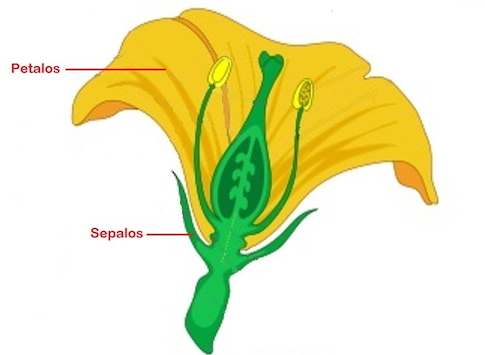

In [3]:
# 1) Leer los datos
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

# El conjunto de datos Iris no tiene encabezado, agregaremos nombres a las columnas en español
nombres_columnas = ['longitud_sepalo', 'ancho_sepalo', 'longitud_petalo', 'ancho_petalo', 'clase']

# Leer desde la URL con pandas
pd_iris = pd.read_csv(url, header=None, names=nombres_columnas)

In [4]:
pd_iris

,longitud_sepalo,ancho_sepalo,longitud_petalo,ancho_petalo,clase
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


# Tablas con medidas descriptivas

In [5]:
# 2) Tabla con medias, medianas y varianzas
estadisticas_descriptivas = pd_iris.describe()
estadisticas_descriptivas

,longitud_sepalo,ancho_sepalo,longitud_petalo,ancho_petalo
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667
std,0.828066,0.433594,1.764420,0.763161
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


# Representación de medidas de centralización

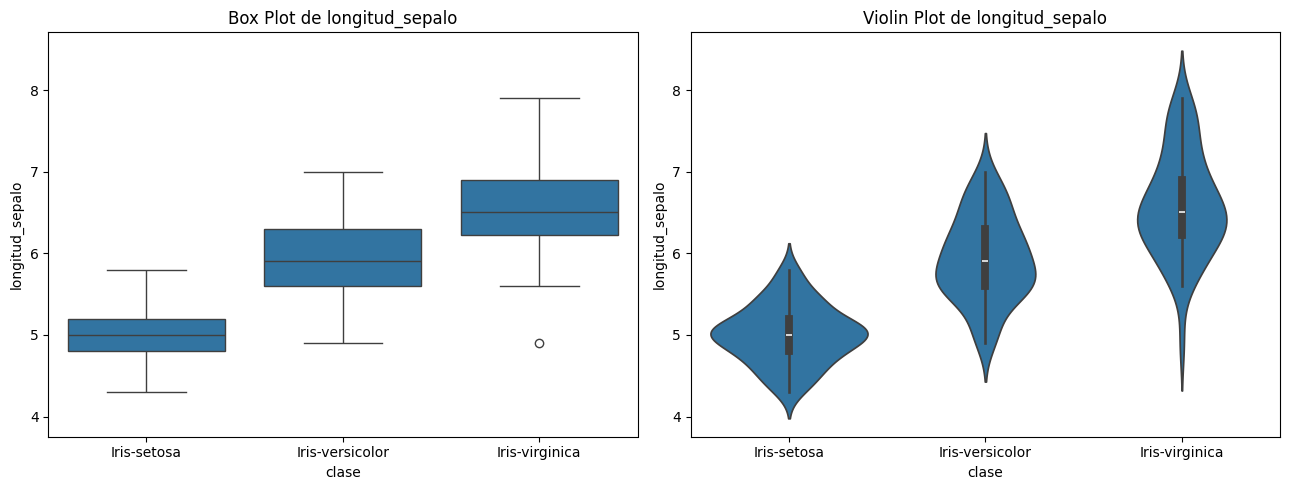

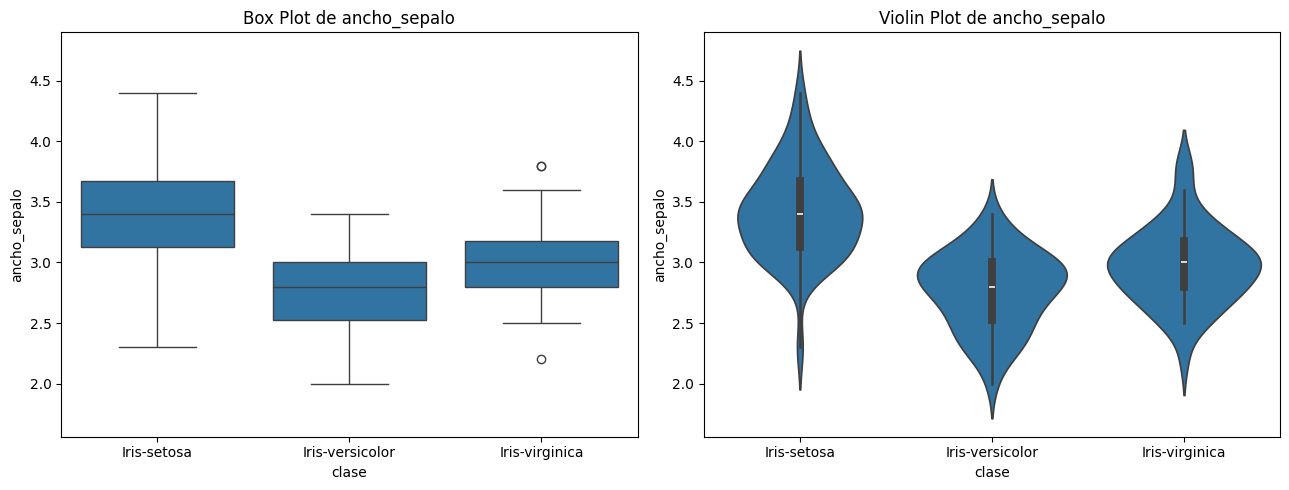

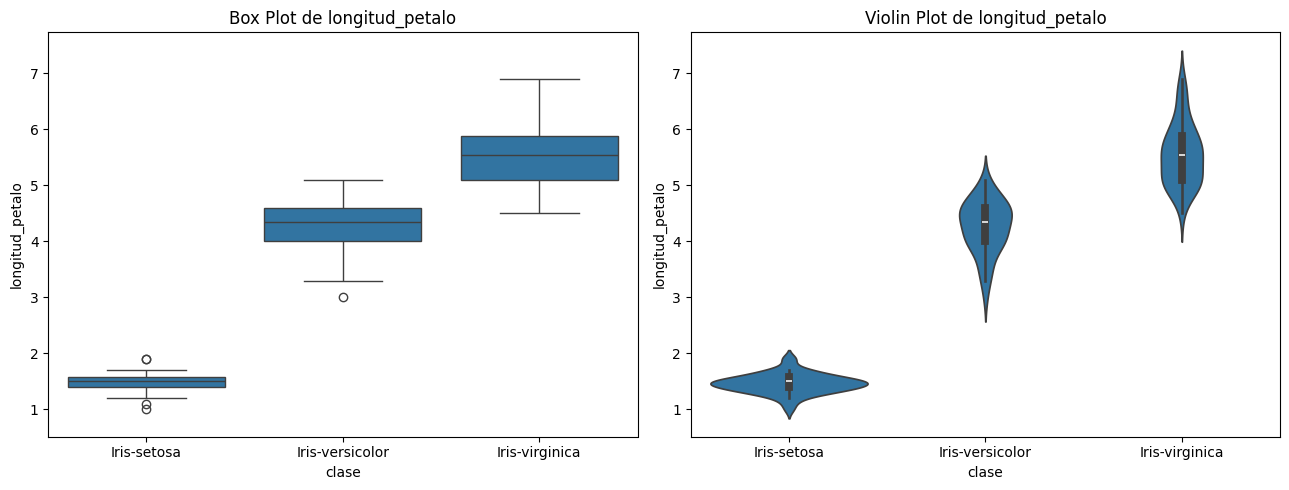

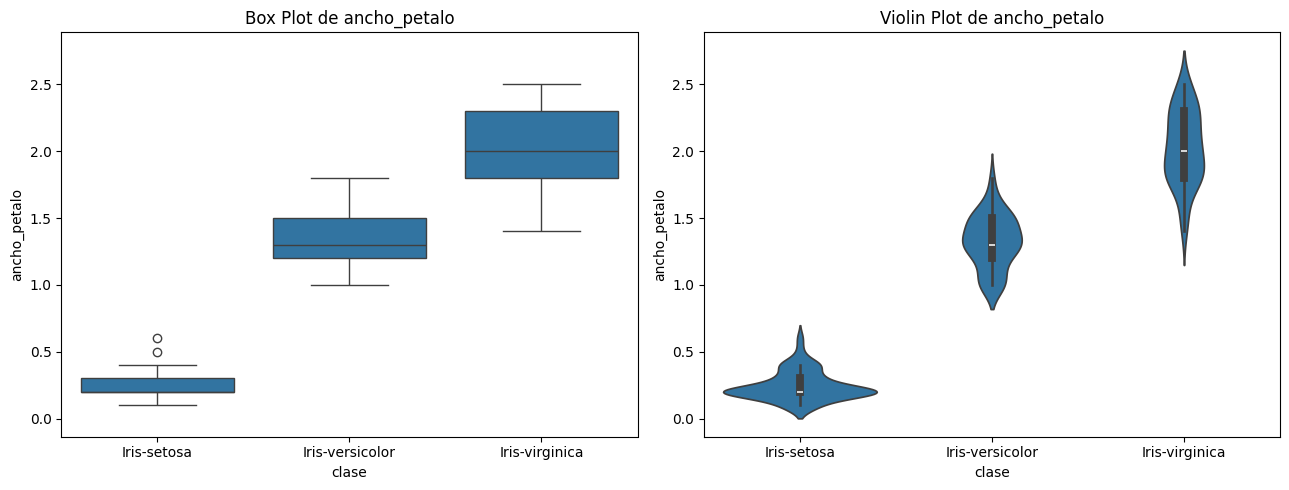

In [12]:
# 3) Representación gráfica con boxplots y violin plots con las mismas escalas en el eje y

caracteristicas = ['longitud_sepalo', 'ancho_sepalo', 'longitud_petalo', 'ancho_petalo']

for feature in caracteristicas:
    plt.figure(figsize=(13, 5))

    # Primero, dibujamos el violin plot y obtenemos los límites del eje y
    plt.subplot(1, 2, 2)
    sns.violinplot(x='clase', y=feature, data=pd_iris)
    plt.title(f'Violin Plot de {feature}')
    y_limits = plt.ylim()  # Obtener los límites del eje y del violin plot
    # Luego, dibujamos el boxplot aplicando los límites del eje y del violin plot
    plt.subplot(1, 2, 1)
    sns.boxplot(x='clase', y=feature, data=pd_iris)
    plt.ylim(y_limits)  # Aplicar los mismos límites del eje y del violin plot
    plt.title(f'Box Plot de {feature}')

    plt.tight_layout()
    plt.show()

# Representación de la dispersión

En el caso de la dispersión, las representaciones más interesantes son aquellas que nos muestran la variabilidad conjunta de las variables. Así, vamos a estudiar la dispersión por parejas de variables.

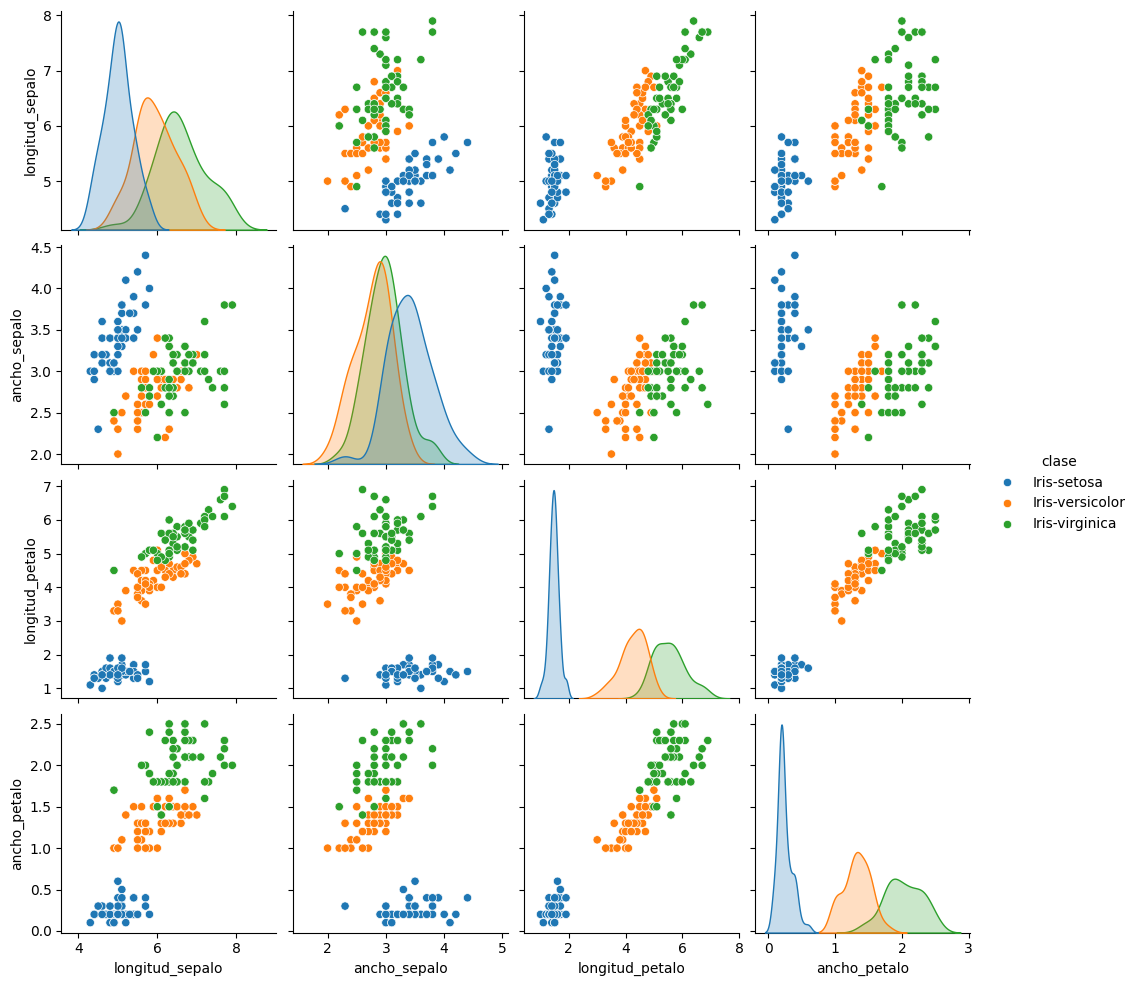

In [18]:
#  Gráficos de dispersión de todas las parejas de variables
sns.pairplot(pd_iris, hue='clase', diag_kind='kde')
plt.show()

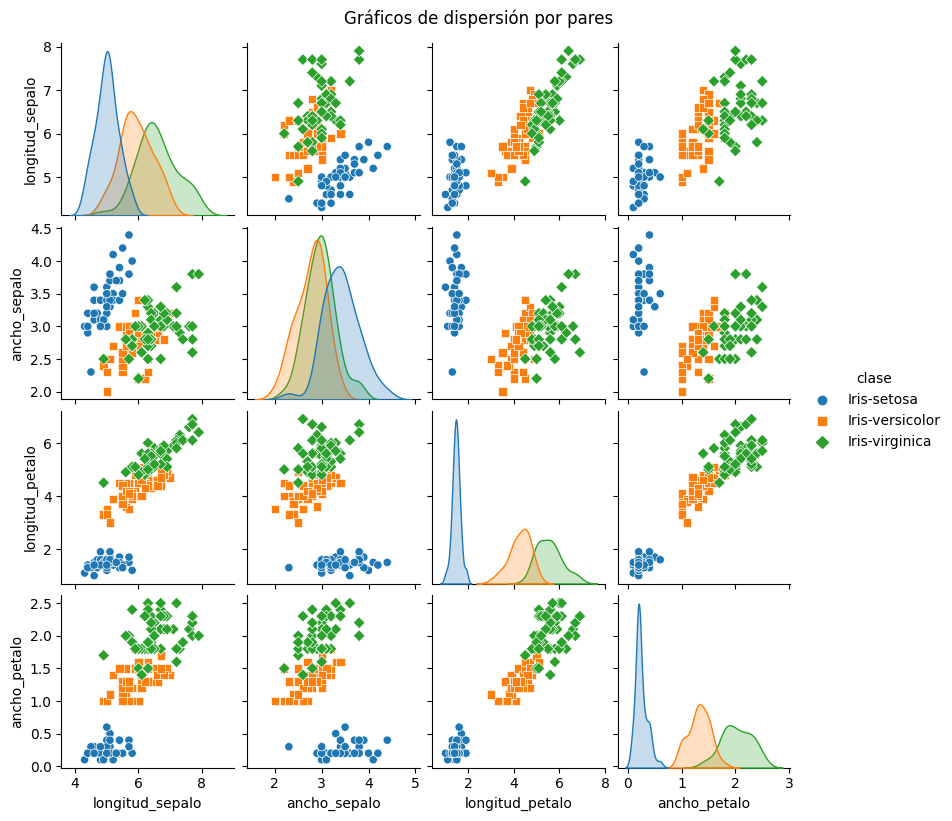

In [ ]:
# Ahora representamos cada una de las clases con un color
___
plt.suptitle('Gráficos de dispersión por pares', y=1.02)
plt.show()

De una manera más sintética, y a menudo más expresiva, podemos representar un mapa de calor con los coeficientes de correlación

In [7]:
correlacion = pd_iris.drop('clase', axis=1).corr()
correlacion


,longitud_sepalo,ancho_sepalo,longitud_petalo,ancho_petalo
longitud_sepalo,1.000000,-0.109369,0.871754,0.817954
ancho_sepalo,-0.109369,1.000000,-0.420516,-0.356544
longitud_petalo,0.871754,-0.420516,1.000000,0.962757
ancho_petalo,0.817954,-0.356544,0.962757,1.000000


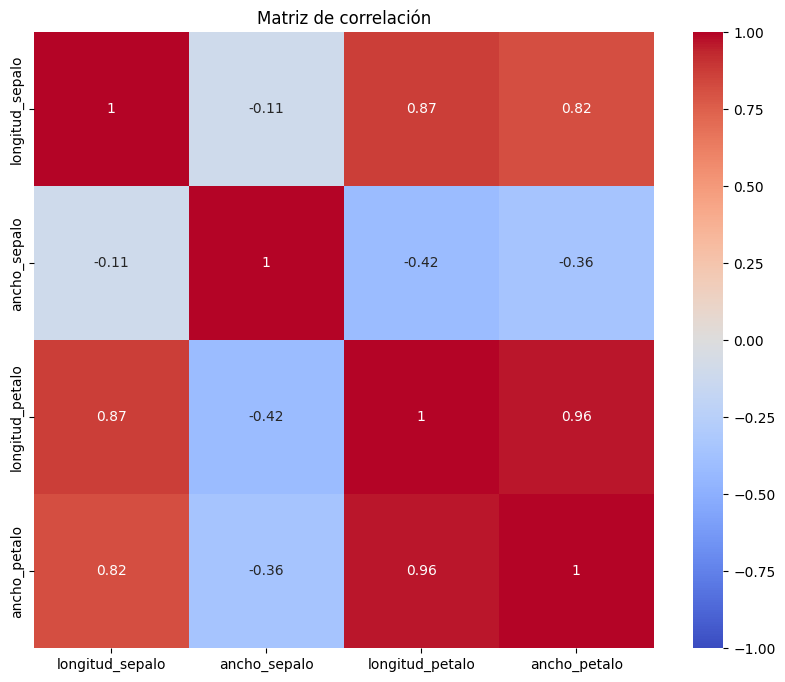

In [8]:
plt.figure(figsize=(10, 8))
sns.heatmap(correlacion, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Matriz de correlación")
plt.show()